In [68]:
# !pip install yfinance
# !pip install matplotlib
# !pip install pandas
# !pip install numpy


In [69]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import datetime
import pytz

In [70]:
pair = ['GS','JPM']

In [71]:
data = yf.download(pair,start=datetime(2020,1,1,tzinfo=pytz.utc), end=datetime(2026,1,1,tzinfo=pytz.utc),multi_level_index=False,)['Close']
data = data.rename(columns ={'GS':'stockA',
                    'JPM':'stockB'})
data.columns.name = None

[*********************100%***********************]  2 of 2 completed


In [72]:
data['spread'] = data['stockA'] / data['stockB']
data

,stockA,stockB,spread
Date,,,
2020-01-02,200.251297,117.313950,1.706969
2020-01-03,197.909683,115.765823,1.709569
2020-01-06,199.935043,115.673775,1.728439
2020-01-07,201.251190,113.707237,1.769907
2020-01-08,203.191147,114.594269,1.773135
...,...,...,...
2025-12-24,897.640198,322.950073,2.779501
2025-12-26,893.954041,321.713867,2.778724
2025-12-29,879.308472,317.632477,2.768320


In [73]:
window = 20

data['z_score'] = (
    (data['spread'] - data['spread'].rolling(window).mean()) 
    / data['spread'].rolling(window).std()
)

<Axes: title={'center': 'Spread between GS and JPM'}, xlabel='Date'>

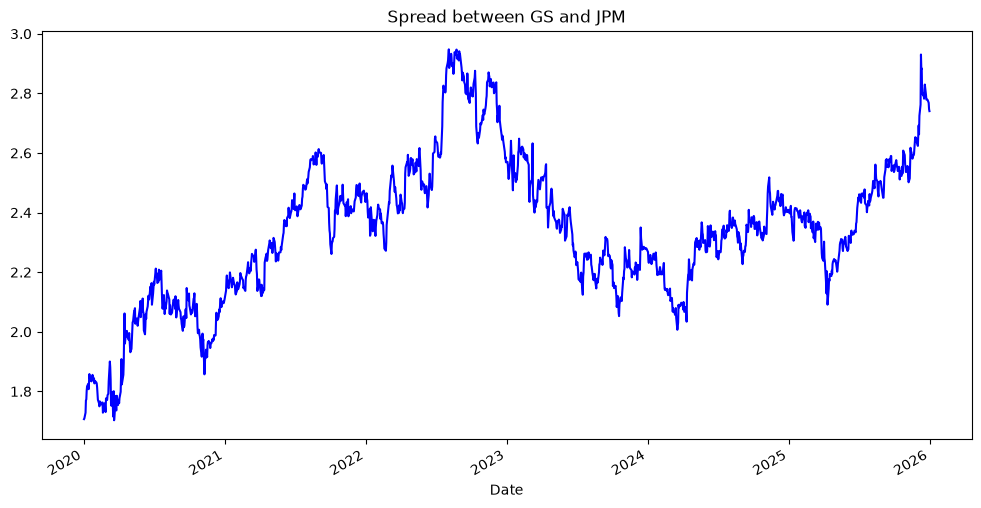

In [74]:
data['spread'].plot(figsize=(12,6), title='Spread between GS and JPM', color='blue')

In [75]:
# Drop NaN rows before running the loop
data = data.dropna(subset=['stockA', 'stockB', 'spread', 'z_score'])

# Also drop any unnamed columns
data = data.loc[:, ~data.columns.astype(str).str.match(r'^\d+$')]

# Reset index
data = data.reset_index(drop=False)

In [76]:
data['signalA'] = 0
data['signalB'] = 0

position = 0

for i in range(len(data)):
    z = data['z_score'].iloc[i]
    if position == 0:
        #if not in trade - look for entry
        if z > 2:
            position = -1

        elif z < -2:
            position = 1
    elif position != 0:
        #if in trade - look for exit
        if abs(z) < 0.5:
            position = 0
    data.loc[i,data.columns.get_loc('signalA')] = position
    data.loc[i,data.columns.get_loc('signalB')] = -position


        

In [77]:
data

,Date,stockA,stockB,spread,z_score,signalA,signalB,5,6
0,2020-01-30,208.634933,113.715607,1.834708,0.532605,0,0,0.0,0.0
1,2020-01-31,203.182602,110.761627,1.834413,0.452949,0,0,0.0,0.0
2,2020-02-03,204.259384,111.606812,1.830170,0.253941,0,0,0.0,0.0
3,2020-02-04,206.763351,113.213493,1.826314,-0.025137,0,0,0.0,0.0
4,2020-02-05,208.780258,115.138199,1.813301,-0.807257,0,0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
1484,2025-12-24,897.640198,322.950073,2.779501,0.179337,0,0,0.0,0.0
1485,2025-12-26,893.954041,321.713867,2.778724,0.101952,0,0,0.0,0.0
1486,2025-12-29,879.308472,317.632477,2.768320,-0.111028,0,0,0.0,0.0
1487,2025-12-30,871.660461,317.308716,2.747042,-0.527200,0,0,0.0,0.0
